In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline
from pprint import pprint

## Motivation

The 2 biggest problem with n gram language models are:
1. Curse of Dimensionality:

    Let's say out vocab V has |V| = $10^5$ for a 10-gram model.
    Then we will have $10^{50}$ weights in the nn to tune.

2. Semantics:

    let's say training set has : 'A cat was eating fish'

    The test set having : 'The dog is eating _' 
    
    An n-gram model will fail to give any probabilty to this test set even though its trained on a semantically similar sentence. 

## Solution

If we embed the word into 30 dim space. 

Context has total of 9 vectors with 30 dimensions each.

We combine them to create a single vector : $9*30=270$ 


In [ ]:
words = open("Indian.txt",'r').read().splitlines()
words[:8]

['Aaban',
 'Aabharan',
 'Aabhas',
 'Aabhat',
 'Aabheer',
 'Abheer',
 'Aabher',
 'Aabi']

In [ ]:
len(words)

53982

In [ ]:
chars= sorted(set([ch.lower() for w in words for ch in w]))
itos = {0:'.'}
for i, ch in enumerate(chars):
    itos[i+1]=ch
stoi = {}
for i,ch in itos.items():
    stoi[ch]=i


In [ ]:
# Building the training data set
# We consider 3 chars to be the context for predicting the next char

# This is the format in which we want the (x,y) : ([ix1, ix2, ix3] , iy)
context_length = 3
x = []
y = []
for w in words[:1]:
    w = w.lower()
    context = [0] * context_length
    w = w + '.'
    for ch in w:
        x.append(context.copy())
        y.append(stoi[ch])
        context[:-1] = context[1:]
        context[-1] = stoi[ch]

x = torch.tensor(x)
y = torch.tensor(y)

In [ ]:
# Now we have to embed these character indexes into vectors
# C is the matrix that contains the vector embeddings corresponding to the characters
emb_dims = 2
g = torch.Generator().manual_seed(2147483647) 
C = torch.randn((27,emb_dims),generator=g)

(-3.5, 3.5)

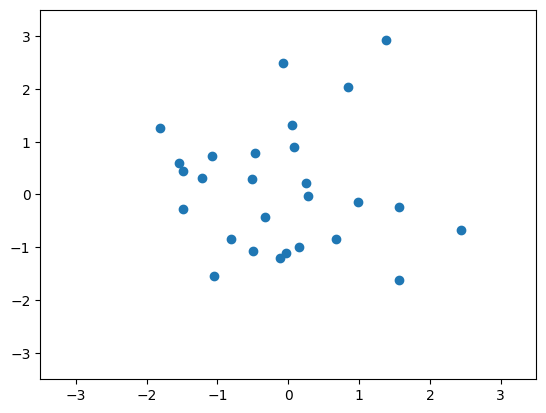

In [ ]:
# Useful only for 2 dimensional embeddings
plt.scatter(C[:,0],C[:,1])
plt.xlim(-3.5,3.5)
plt.ylim(-3.5,3.5)

In [ ]:
# Now we will convert the indexes to embedding using these weights in C
xenc = F.one_hot(x,num_classes=27).float()
emb = xenc@C

In [ ]:
# Better approach
emb = emb.view(-1,(emb_dims*context_length))
emb

tensor([[ 1.5674, -0.2373,  1.5674, -0.2373,  1.5674, -0.2373],
        [ 1.5674, -0.2373,  1.5674, -0.2373, -0.0274, -1.1008],
        [ 1.5674, -0.2373, -0.0274, -1.1008, -0.0274, -1.1008],
        [-0.0274, -1.1008, -0.0274, -1.1008,  0.2859, -0.0296],
        [-0.0274, -1.1008,  0.2859, -0.0296, -0.0274, -1.1008],
        [ 0.2859, -0.0296, -0.0274, -1.1008, -1.2199,  0.3031]])

In [ ]:
# Before passing through this layer, we will concatenate the embedding in a single context
# x_emb = []
# for (e1,e2,e3) in (emb):
#     x_emb.append(([e1[0],e1[1],e2[0],e2[1],e3[0],e3[1]]))
# x_emb = torch.tensor(x_emb)
# print(x_emb)


tensor([[ 1.5674, -0.2373,  1.5674, -0.2373,  1.5674, -0.2373],
        [ 1.5674, -0.2373,  1.5674, -0.2373, -0.0274, -1.1008],
        [ 1.5674, -0.2373, -0.0274, -1.1008, -0.0274, -1.1008],
        [-0.0274, -1.1008, -0.0274, -1.1008,  0.2859, -0.0296],
        [-0.0274, -1.1008,  0.2859, -0.0296, -0.0274, -1.1008],
        [ 0.2859, -0.0296, -0.0274, -1.1008, -1.2199,  0.3031]])


In [ ]:
# We want to create a hidden layer in between the input (individual tensors) and the output (score for each next character)
# Arbitrarily we choose the hidden layer to have 100 nodes
W = torch.randn((6,100),generator=g)
b = torch.randn(100,generator=g)
x_hide = emb @ W + b

In [ ]:
# Now the lsat layer, in which these 100 nodes are the input and the score for each character is the op
W1 = torch.randn((100,27),generator=g)

